# Used Car Price Prediction

A complete machine learning project: problem framing, EDA, cleaning, preprocessing,
model building, evaluation, hyperparameter tuning, and saving the final model for
deployment in a Streamlit app.


## 1. Problem Statement

**Problem:** Pricing a used car is hard — resale value depends on many interacting
factors (brand, age, mileage, engine specs, accident history, title status, etc.)
that are difficult to weigh manually or with simple rules.

**Business Objective:** Build a regression model that predicts a used car's fair
market **price** from its listed attributes, so that:
- Sellers can price a car competitively instead of guessing.
- Buyers can spot listings that are over- or under-priced.
- A marketplace/dealership can auto-suggest a price when a listing is created.

This is a **supervised regression problem** — the target variable is `price`
(continuous).


## 2. Data Collection

- **File:** `data/used_cars.csv`
- **Size:** ~4,009 rows × 12 columns.
- **Nature of data:** Real used-car listing data (not synthetic) — brand, model,
  model year, mileage, fuel type, engine description, transmission, exterior/interior
  color, accident history, title status, and price all come from real ads. The schema
  matches the widely-used "Used Car Price Prediction Dataset" (commonly hosted on
  Kaggle); confirm/attach the exact dataset link in your submission if attribution is
  required, since the file was supplied directly for this project.
- **Target variable:** `price`


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json, os

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
%matplotlib inline


In [2]:
df = pd.read_csv("data/used_cars.csv")
df.head()


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


## 3. Data Understanding

In [3]:
print("Shape:", df.shape)
df.dtypes


Shape: (4009, 12)


brand           object
model           object
model_year       int64
milage          object
fuel_type       object
engine          object
transmission    object
ext_col         object
int_col         object
accident        object
clean_title     object
price           object
dtype: object

In [4]:
df.columns.tolist()


['brand',
 'model',
 'model_year',
 'milage',
 'fuel_type',
 'engine',
 'transmission',
 'ext_col',
 'int_col',
 'accident',
 'clean_title',
 'price']

In [5]:
# Target variable
df["price"].head(10)


0    $10,300
1    $38,005
2    $54,598
3    $15,500
4    $34,999
5    $14,798
6    $31,000
7     $7,300
8    $41,927
9    $69,950
Name: price, dtype: object

**Observations**
- `price` and `milage` are stored as formatted strings (`"$10,300"`, `"51,000 mi."`)
  and must be converted to numeric before they're usable.
- `engine` is a free-text description that bundles horsepower and engine size — both
  useful numeric signals hidden inside text.
- `model`, `ext_col`, `int_col` are high-cardinality text fields.


## 4. Exploratory Data Analysis (EDA)

### 4.1 Summary Statistics

In [6]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,4009,57,Ford,386,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,4009,1898,M3 Base,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model_year,4009.0,NaN,NaN,NaN,2015.51559,6.104816,1974.0,2012.0,2017.0,2020.0,2024.0
milage,4009,2818,"110,000 mi.",16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel_type,3839,7,Gasoline,3309,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,4009,1146,2.0L I4 16V GDI DOHC Turbo,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4009,62,A/T,1037,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ext_col,4009,319,Black,905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
int_col,4009,156,Black,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
accident,3896,2,None reported,2910,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4.2 Missing Values

In [7]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct}).query("missing_count > 0")


,missing_count,missing_pct
fuel_type,170,4.24
accident,113,2.82
clean_title,596,14.87


*Insight: `clean_title` (~15% missing) and `fuel_type` (~4% missing) have the most gaps; `accident` is missing for ~3% of rows. None are missing enough to justify dropping the column outright.*

### 4.3 Duplicates

In [8]:
dupe_count = df.duplicated().sum()
print(f"Duplicate rows: {dupe_count}")


Duplicate rows: 0


### 4.4 Univariate Analysis

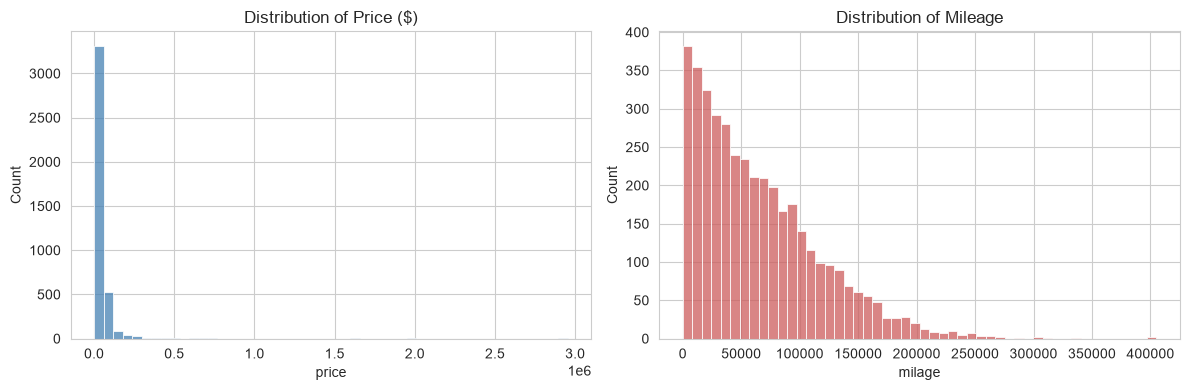

In [9]:
# Clean price/milage just for plotting (proper cleaning happens in Section 5)
_price_num = df["price"].replace(r"[\$,]", "", regex=True).astype(float)
_milage_num = df["milage"].replace(r"[^0-9]", "", regex=True).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(_price_num, bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Price ($)")
sns.histplot(_milage_num, bins=50, ax=axes[1], color="indianred")
axes[1].set_title("Distribution of Mileage")
plt.tight_layout()
plt.show()


*Insight: Price is strongly right-skewed — most cars sell under \$60k, but a long tail of exotics stretches into the hundreds of thousands. This motivates capping extreme outliers later.*

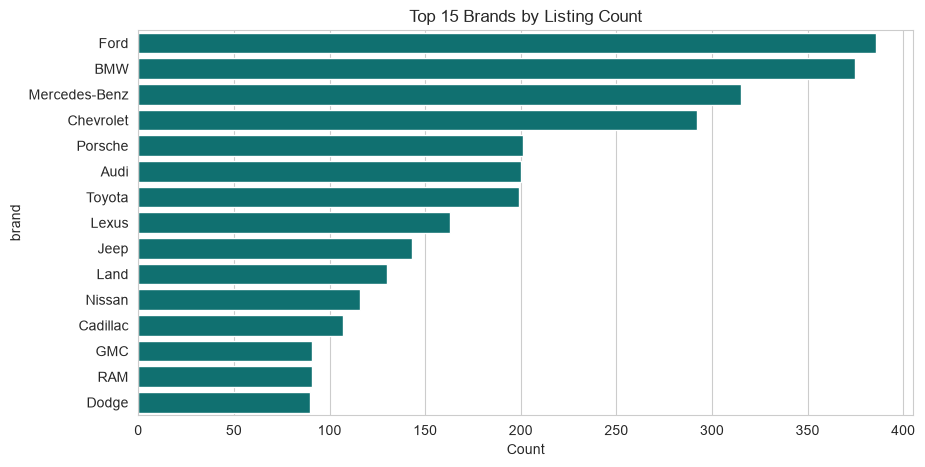

In [10]:
top_brands = df["brand"].value_counts().head(15)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_brands.values, y=top_brands.index, color="teal")
plt.title("Top 15 Brands by Listing Count")
plt.xlabel("Count")
plt.show()


*Insight: Ford, Chevrolet, and BMW dominate listing volume, so the model will see far more training examples for mainstream brands than for exotics like Bugatti or Rolls-Royce.*

### 4.5 Bivariate Analysis

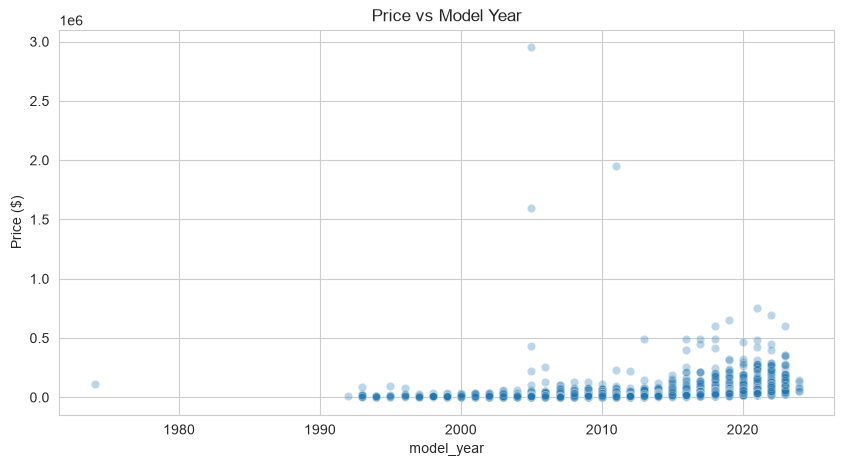

In [11]:
plt.figure(figsize=(10, 5))
sns.scatterplot(x=df["model_year"], y=_price_num, alpha=0.3)
plt.title("Price vs Model Year")
plt.ylabel("Price ($)")
plt.show()


*Insight: Newer cars command higher prices, as expected, but the relationship is noisy — brand and condition clearly matter as much as age.*

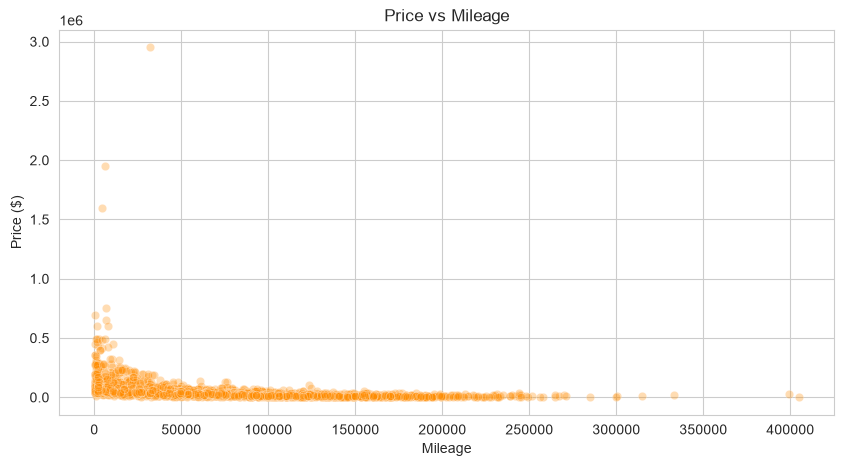

In [12]:
plt.figure(figsize=(10, 5))
sns.scatterplot(x=_milage_num, y=_price_num, alpha=0.3, color="darkorange")
plt.title("Price vs Mileage")
plt.xlabel("Mileage")
plt.ylabel("Price ($)")
plt.show()


*Insight: Price falls off sharply as mileage increases, most steeply in the first ~100k miles — confirms mileage will be an important predictive feature.*

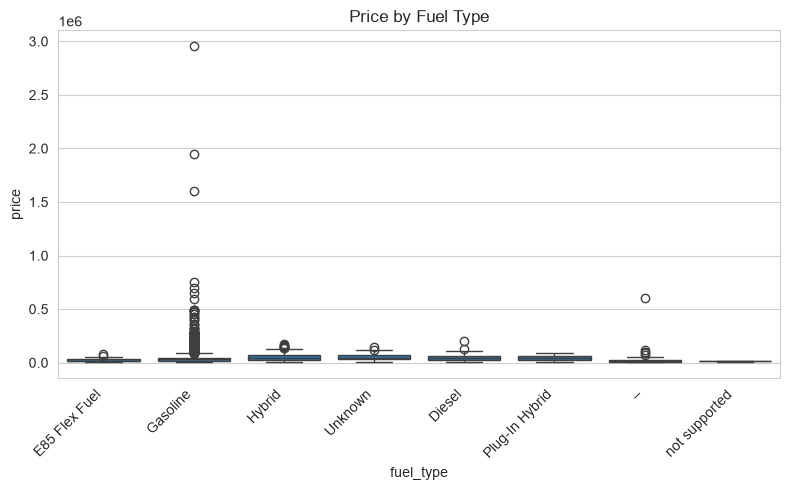

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["fuel_type"].fillna("Unknown"), y=_price_num)
plt.xticks(rotation=45, ha="right")
plt.title("Price by Fuel Type")
plt.tight_layout()
plt.show()


*Insight: Hybrid/Electric listings skew higher in price than plain Gasoline — partly newer average age, partly a genuine EV price premium.*

### 4.6 Correlation Analysis

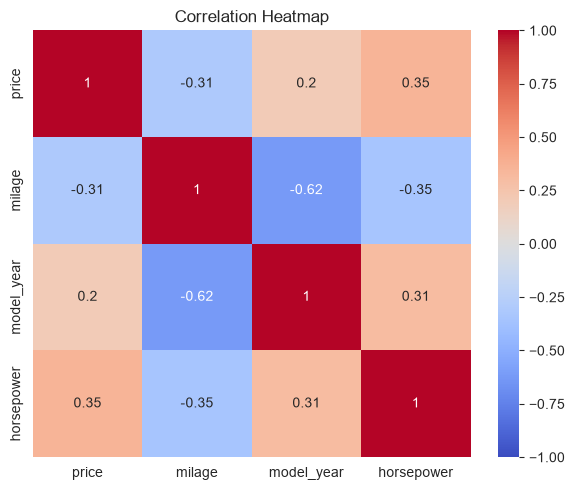

In [14]:
_engine_hp = df["engine"].str.extract(r"([\d\.]+)\s*HP").astype(float)
_corr_df = pd.DataFrame({
    "price": _price_num,
    "milage": _milage_num,
    "model_year": df["model_year"],
    "horsepower": _engine_hp[0]
})

plt.figure(figsize=(6, 5))
sns.heatmap(_corr_df.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


*Insight: `milage` correlates negatively with price, `model_year` and `horsepower` correlate positively — all three are worth keeping as model features.*

## 5. Data Cleaning

- **Missing values:** `fuel_type` filled with `"Unknown"` (corrected to `"Electric"`
  where the engine text says so); `accident`/`clean_title` converted to binary flags,
  treating missing as "no accident reported" / "not confirmed clean" respectively —
  reasonable defaults since these are the majority classes.
- **Duplicates:** removed if present (checked above).
- **Incorrect data types:** `price` and `milage` converted from formatted strings to
  floats.
- **Outliers:** prices above the 99.5th percentile capped/removed (extreme
  ultra-luxury listings behave like a different market and would distort training).


In [15]:
data = df.copy()

# Remove exact duplicate rows
data = data.drop_duplicates()

# --- Fix data types ---
data["price"] = data["price"].replace(r"[\$,]", "", regex=True).astype(float)
data["milage"] = data["milage"].replace(r"[^0-9]", "", regex=True).astype(float)

# --- Handle missing values ---
data["fuel_type"] = data["fuel_type"].fillna("Unknown")
data.loc[data["engine"].str.contains("Electric", case=False, na=False), "fuel_type"] = "Electric"

data["accident_reported"] = data["accident"].apply(
    lambda x: 1 if isinstance(x, str) and "least" in x.lower() else 0
)
data["clean_title_flag"] = data["clean_title"].apply(lambda x: 1 if x == "Yes" else 0)

# --- Handle outliers: cap extreme prices at the 99.5th percentile ---
data = data[data["price"] > 0]
price_cap = data["price"].quantile(0.995)
before = len(data)
data = data[data["price"] <= price_cap]
print(f"Removed {before - len(data)} extreme price outliers (cap = ${price_cap:,.0f})")


Removed 21 extreme price outliers (cap = $398,304)


## 6. Data Preprocessing

- **Feature engineering:** `car_age` from `model_year`; `horsepower` and
  `engine_size_l` regex-extracted from the free-text `engine` field.
- **Feature selection:** `model`, `ext_col`, `int_col` are dropped — 1,885 / 315 / 150
  unique values respectively, which would explode the one-hot feature space for
  limited gain; `brand` retains most of the useful signal.
- **Encoding:** One-Hot Encoding for nominal categoricals (`brand`, `fuel_type`,
  `transmission`, `accident_reported`, `clean_title_flag`) — used because these
  categories have no inherent order.
- **Feature scaling:** `StandardScaler` on numeric features — needed for the Linear
  Regression baseline; harmless for the tree-based models, so one shared pipeline
  works for all three.


In [16]:
data["car_age"] = 2024 - data["model_year"]
data["horsepower"] = data["engine"].str.extract(r"([\d\.]+)\s*HP").astype(float)
data["engine_size_l"] = data["engine"].str.extract(r"([\d\.]+)\s*L\b").astype(float)

NUM_FEATURES = ["milage", "car_age", "horsepower", "engine_size_l"]
CAT_FEATURES = ["brand", "fuel_type", "transmission", "accident_reported", "clean_title_flag"]

model_df = data[NUM_FEATURES + CAT_FEATURES + ["price"]].reset_index(drop=True)
print(f"horsepower missing: {model_df['horsepower'].isna().sum()}  "
      f"engine_size_l missing: {model_df['engine_size_l'].isna().sum()}")
model_df.head()


horsepower missing: 793  engine_size_l missing: 373


,milage,car_age,horsepower,engine_size_l,brand,fuel_type,transmission,accident_reported,clean_title_flag,price
0,51000.0,11,300.0,3.7,Ford,E85 Flex Fuel,6-Speed A/T,1,1,10300.0
1,34742.0,3,NaN,3.8,Hyundai,Gasoline,8-Speed Automatic,1,1,38005.0
2,22372.0,2,NaN,NaN,Lexus,Gasoline,Automatic,0,0,54598.0
3,88900.0,9,354.0,3.5,INFINITI,Electric,7-Speed A/T,0,1,15500.0
4,9835.0,3,NaN,2.0,Audi,Gasoline,8-Speed Automatic,0,0,34999.0


In [17]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, NUM_FEATURES),
    ("cat", categorical_transformer, CAT_FEATURES)
])


## 7. Train-Test Split

80/20 split with a fixed random seed for reproducibility.


In [18]:
X = model_df.drop(columns="price")
y = model_df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (3190, 9)  Test shape: (798, 9)


## 8. Model Building

Three regression models are trained on the same preprocessing pipeline so their
performance is directly comparable:
- **Linear Regression** — simple baseline.
- **Random Forest Regressor** — captures non-linear feature interactions.
- **Gradient Boosting Regressor** — sequential boosting, often strong on tabular data.


In [19]:
candidates = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
}

fitted_pipelines = {}
for name, model in candidates.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", model)])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe


## 9. Model Evaluation

Metrics used (regression task): **MAE, MSE, RMSE, R² Score**.


In [20]:
def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

eval_results = {}
for name, pipe in fitted_pipelines.items():
    preds = pipe.predict(X_test)
    eval_results[name] = evaluate(y_test, preds)

results_df = pd.DataFrame(eval_results).T.sort_values("R2", ascending=False)
results_df


,MAE,MSE,RMSE,R2
Gradient Boosting,9722.980653,2.758249e+08,16607.978075,0.830481
Random Forest,9165.217584,3.015686e+08,17365.730265,0.814660
Linear Regression,13471.583025,5.137632e+08,22666.345025,0.684248


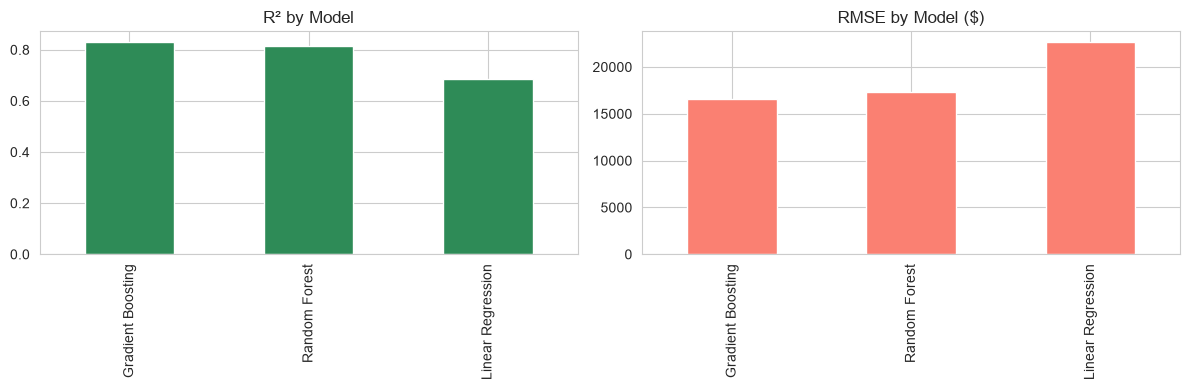

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results_df["R2"].plot(kind="bar", ax=axes[0], color="seagreen")
axes[0].set_title("R² by Model")
results_df["RMSE"].plot(kind="bar", ax=axes[1], color="salmon")
axes[1].set_title("RMSE by Model ($)")
plt.tight_layout()
plt.show()


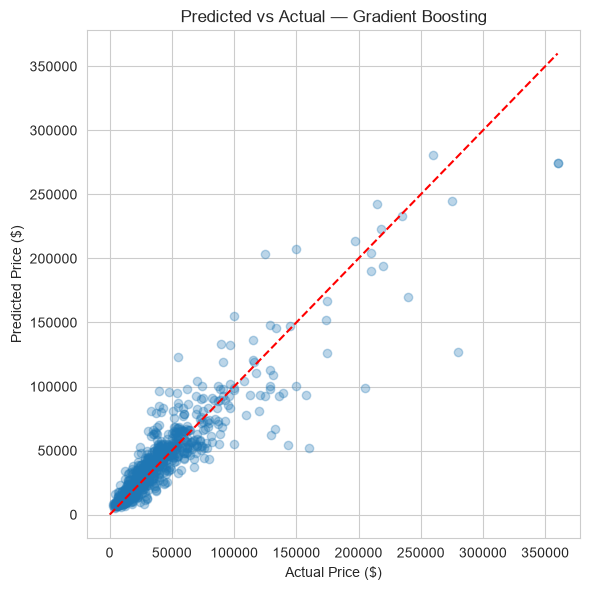

Best baseline model: Gradient Boosting


In [22]:
best_name = results_df["R2"].idxmax()
best_pipe = fitted_pipelines[best_name]
best_preds = best_pipe.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_preds, alpha=0.3)
lims = [0, max(y_test.max(), best_preds.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title(f"Predicted vs Actual — {best_name}")
plt.tight_layout()
plt.show()

print("Best baseline model:", best_name)


## 10. Hyperparameter Tuning

`RandomizedSearchCV` (3-fold, R² scoring) tunes the best baseline model's key
hyperparameters. A randomized search is used instead of an exhaustive grid search to
keep runtime reasonable while still covering a wide range of settings.


In [23]:
if best_name == "Random Forest":
    base_model = RandomForestRegressor(random_state=42, n_jobs=-1)
    param_dist = {
        "regressor__n_estimators": [150, 250, 350],
        "regressor__max_depth": [8, 12, 16],
        "regressor__min_samples_split": [2, 5],
        "regressor__min_samples_leaf": [1, 2],
    }
elif best_name == "Gradient Boosting":
    base_model = GradientBoostingRegressor(random_state=42)
    param_dist = {
        "regressor__n_estimators": [150, 250],
        "regressor__max_depth": [2, 3],
        "regressor__learning_rate": [0.05, 0.1],
        "regressor__subsample": [0.8, 1.0],
    }
else:
    base_model = LinearRegression()
    param_dist = {}

tuned_pipe = Pipeline([("preprocessor", preprocessor), ("regressor", base_model)])

if param_dist:
    search = RandomizedSearchCV(
        tuned_pipe, param_distributions=param_dist,
        n_iter=6, cv=3, scoring="r2", random_state=42, n_jobs=-1
    )
    search.fit(X_train, y_train)
    best_pipe = search.best_estimator_
    print("Best params:", search.best_params_)
else:
    best_pipe = tuned_pipe.fit(X_train, y_train)

tuned_preds = best_pipe.predict(X_test)
tuned_metrics = evaluate(y_test, tuned_preds)
print("Tuned model metrics:", tuned_metrics)


Best params: {'regressor__subsample': 0.8, 'regressor__n_estimators': 250, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.1}
Tuned model metrics: {'MAE': 9158.162370818893, 'MSE': 263627010.93630338, 'RMSE': np.float64(16236.594807295753), 'R2': 0.8379781640263528}


In [24]:
cv_scores = cross_val_score(best_pipe, X, y, cv=5, scoring="r2", n_jobs=-1)
print("CV R2 scores:", np.round(cv_scores, 3))
print(f"Mean R2: {cv_scores.mean():.3f}  (+/- {cv_scores.std():.3f})")


CV R2 scores: [0.759 0.786 0.839 0.845 0.845]
Mean R2: 0.815  (+/- 0.036)


### Feature Importance

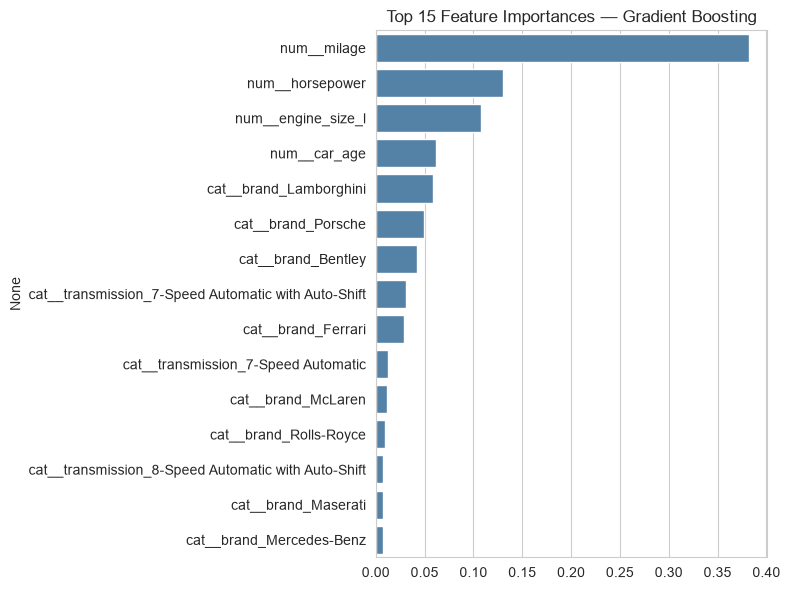

In [25]:
if hasattr(best_pipe.named_steps["regressor"], "feature_importances_"):
    feature_names = best_pipe.named_steps["preprocessor"].get_feature_names_out()
    importances = best_pipe.named_steps["regressor"].feature_importances_
    fi = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(15)

    plt.figure(figsize=(8, 6))
    sns.barplot(x=fi.values, y=fi.index, color="steelblue")
    plt.title(f"Top 15 Feature Importances — {best_name}")
    plt.tight_layout()
    plt.show()
else:
    print("Selected model has no feature_importances_ attribute (e.g. Linear Regression).")


## 11. Save the Model

The full pipeline (preprocessing + trained model) is saved with `joblib`, so it can
be loaded and used directly on raw input rows — no need to re-run preprocessing by
hand. This is the same file used by `app.py` (Streamlit) and `predict.py`.


In [26]:
os.makedirs("models", exist_ok=True)

tuned_metrics["cv_r2_mean"] = float(cv_scores.mean())
tuned_metrics["cv_r2_std"] = float(cv_scores.std())
tuned_metrics["model_name"] = best_name

joblib.dump(best_pipe, "models/best_model.joblib")
with open("models/metrics.json", "w") as f:
    json.dump(tuned_metrics, f, indent=2)

print("Saved model to models/best_model.joblib")
print("Saved metrics to models/metrics.json")


Saved model to models/best_model.joblib
Saved metrics to models/metrics.json


### Sanity check: predict on a new car

In [27]:
sample = pd.DataFrame([{
    "milage": 30000,
    "car_age": 3,
    "horsepower": 300,
    "engine_size_l": 3.5,
    "brand": "Toyota",
    "fuel_type": "Gasoline",
    "transmission": "Automatic",
    "accident_reported": 0,
    "clean_title_flag": 1
}])

loaded_model = joblib.load("models/best_model.joblib")
predicted_price = loaded_model.predict(sample)[0]
print(f"Predicted price: ${predicted_price:,.0f}")


Predicted price: $37,705


## Conclusion & Next Steps

- After cleaning (`price`/`milage` string parsing, engine-text extraction) and
  encoding, tree-based ensembles clearly beat plain Linear Regression, confirming
  price depends on non-linear interactions between mileage, age, brand, and engine
  specs.
- `milage`, `car_age`, and `horsepower` dominate feature importance, alongside brand
  (luxury brands carry a price premium independent of specs).
- Model, saved as `models/best_model.joblib`, is consumed by `app.py` (Streamlit UI)
  and `predict.py` (CLI) — see `README.md` for how to run and deploy them.

**Possible next steps**
- Target/frequency-encode `model` (currently dropped) to recover trim-level signal.
- Try log-transforming `price` for the linear baseline.
- Expand hyperparameter search (more iterations / full grid) given more compute time.
- Investigate remaining high-mileage exotic-car outliers more closely.
